# Entrega 3 · Modelado — ¿Gana el underdog?

**Pregunta de investigación**: ¿ganará el equipo no favorito (*underdog*) el próximo partido, según las métricas previas
del encuentro y de sus jugadores?

Este notebook parte del Silver de la Entrega 2 (`include/data/silver/underdog_dataset.parquet`, 17.959 partidos × 31
columnas) y elige **el modelo que va a usar la aplicación de la Entrega 4**. Se corre de arriba hacia abajo, con una
semilla definida en la primera celda de código.

### Qué cambió desde la Entrega 2

Ni el objetivo ni el dataset cambiaron: el target sigue siendo `gano_no_favorito` y entran las 12 columnas que la Entrega 2
dejó en amarillo/verde. Lo que sí corregimos es la lectura: en esta entrega **todos los gráficos tienen título, ejes en
castellano y nombres de columna legibles** (en vez de `nofav_xi_overall_mean_gap`, «Dif. rating medio del XI»).

### Hoja de ruta

| Parte | Qué pasa | Qué deja |
|---|---|---|
| **1** | El planteo: qué predecimos, la métrica, la partición y la validación | la métrica declarada, el test apartado y los pedazos de la validación |
| **2** | El piso y el rival | el número que hay que superar |
| **3** | La comparación: logística contra tres familias, cada una con su grilla | la tabla con media y desvío, y el modelo elegido |
| **4** | El ajuste del elegido | la tabla completa de la grilla |
| **5** | Las columnas: qué aporta cada una | las columnas que no sirvieron, con el número |
| **6** | El desbalance: `class_weight` y el umbral | la regla de decisión |
| **7** | El modelo final, medido **una vez** sobre el test | dónde se equivoca y en qué se apoya |
| **8** | Fuga, lo que no anduvo y el modelo guardado | el archivo para la Entrega 4 |

In [1]:
# La semilla, definida una sola vez y pasada a todo lo que la acepte
SEMILLA = 42

import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(SEMILLA)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})

# el notebook vive en notebooks/: la raíz del repo es la carpeta de arriba
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from include.config import AUDIT_DIR, DATA_DIR, SILVER_DATASET_PATH
from include.src.columns import FEATURE_COLUMNS, TARGET_COLUMN

import sklearn
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 2.3.3


In [2]:
# Nombres legibles para tablas y gráficos. "Dif." = underdog − favorito: positivo quiere decir que el underdog es mejor.
NOMBRES = {
    "prob_no_favorito":               "Prob. implícita del underdog",
    "prob_draw":                      "Prob. implícita del empate",
    "nofav_xi_overall_mean_gap":      "Dif. rating medio del XI",
    "nofav_top3_overall_gap":         "Dif. rating de los 3 mejores",
    "nofav_best_overall_gap":         "Dif. mejor jugador",
    "nofav_worst_overall_gap":        "Dif. peor titular",
    "nofav_def_overall_gap":          "Dif. rating de la defensa",
    "nofav_mid_overall_gap":          "Dif. rating del mediocampo",
    "nofav_att_overall_gap":          "Dif. rating del ataque",
    "nofav_best_finishing_gap":       "Dif. mejor definición",
    "nofav_best_reactions_gap":       "Dif. mejores reacciones",
    "nofav_best_marking_gap":         "Dif. mejor marca",
    # las 11 en rojo de la Entrega 2: salieron del modelo, acá se vuelven a probar
    "nofav_gk_overall_gap":           "Dif. rating del arquero",
    "nofav_fastest_sprint_speed_gap": "Dif. jugador más rápido",
    "nofav_strongest_strength_gap":   "Dif. jugador más fuerte",
    "nofav_overall_std_gap":          "Dif. dispersión del XI",
    "nofav_xi_age_mean_gap":          "Dif. edad media del XI",
    "nofav_xi_height_mean_gap":       "Dif. altura media del XI",
    "jornada":                        "Jornada",
    "liga":                           "Liga",
    "equipo_favorito":                "Favorito local / visitante",
}
CLASES = ["No ganó el underdog", "Ganó el underdog"]

MERCADO   = ["prob_no_favorito", "prob_draw"]
JUGADORES = [c for c in FEATURE_COLUMNS if c not in MERCADO]
ROJAS_NUM = ["nofav_gk_overall_gap", "nofav_fastest_sprint_speed_gap", "nofav_strongest_strength_gap",
             "nofav_overall_std_gap", "nofav_xi_age_mean_gap", "nofav_xi_height_mean_gap", "jornada"]
ROJAS_CAT = ["liga", "equipo_favorito"]
assert set(MERCADO + JUGADORES) == set(FEATURE_COLUMNS)

def legible(columnas):
    return [NOMBRES.get(c, c) for c in columnas]

print(len(MERCADO), "de mercado +", len(JUGADORES), "de jugadores =", len(FEATURE_COLUMNS), "features de la Entrega 2")

2 de mercado + 10 de jugadores = 12 features de la Entrega 2


## Parte 1 — El planteo

### 1.1 Qué predecimos

Una fila = un partido. El objetivo es `gano_no_favorito`: 1 si ganó el underdog, 0 si empató o perdió. El *underdog* es el
equipo con menor probabilidad implícita de ganar según las cuotas pre-partido, y solo entran partidos donde la diferencia con
el favorito es mayor a 0,05 (decisión §4 de la Entrega 2). Es **clasificación binaria**.

Las filas se ordenan por fecha desde acá: la validación temporal lo necesita.

In [3]:
df = (pd.read_parquet(SILVER_DATASET_PATH)
        .sort_values(["fecha", "match_id"])
        .reset_index(drop=True))
df[TARGET_COLUMN] = df[TARGET_COLUMN].astype(int)

print(f"{df.shape[0]:,} partidos × {df.shape[1]} columnas, del {df['fecha'].min():%d/%m/%Y} al {df['fecha'].max():%d/%m/%Y}")
(df[TARGET_COLUMN].value_counts().rename(index=dict(enumerate(CLASES)))
   .to_frame("partidos").assign(proporcion=lambda t: (t["partidos"] / t["partidos"].sum()).round(4)))

17,959 partidos × 31 columnas, del 09/08/2008 al 17/05/2016


,partidos,proporcion
gano_no_favorito,,
No ganó el underdog,14305,0.7965
Ganó el underdog,3654,0.2035


### 1.2 La métrica, declarada antes de elegir

**Métrica principal: ROC-AUC. Secundaria: log-loss.** El porqué:

- **Accuracy no sirve.** Un modelo que contesta siempre «no gana» acierta el 80% sin mirar nada (se mide en la Parte 2). La
  accuracy esconde justamente a la clase que nos interesa, la chica.
- **Qué error es más caro.** La aplicación de la Entrega 4 no tiene que decir «sí/no»: tiene que decir **qué tan probable** es
  la sorpresa y ordenar los partidos de más a menos sorprendibles. El error caro es **ordenar mal**: poner como sorpresa
  probable un partido que no lo es, y viceversa. Eso es lo que mide el **ROC-AUC**: la probabilidad de que, tomando un partido
  que el underdog ganó y otro que no, el modelo le dé más chance al primero. No depende del umbral ni del desbalance, y el
  piso vale exactamente 0,5.
- **Log-loss** mira otra cosa: si la probabilidad que se muestra es **creíble** (calibrada). Si el modelo dice 30%, que gane
  el 30% de esas veces. Un modelo puede ordenar bien y mentir en las probabilidades: por eso va de secundaria.
- La pregunta de sí/no (con qué umbral decimos «gana el underdog») se decide recién en la Parte 6, con el f1 de la clase
  positiva, sobre la validación.

### 1.3 La partición: el test es la última temporada

Los partidos **están en el tiempo**, y la aplicación va a predecir partidos **que todavía no se jugaron** con un modelo entrenado
con los anteriores. Entonces el test se separa igual: **la temporada 2015/16 completa** (la última de la base) queda afuera y
no se mira hasta la Parte 7. Se entrena y se elige con 2008/09 a 2014/15.

Separar el test al azar mezclaría partidos de 2016 en el entrenamiento para predecir partidos de 2010: el modelo vería el
futuro (cómo cambian los ratings FIFA, las cuotas de cada época, qué casa de apuestas se usa).

In [4]:
TEST_TEMPORADA = "2015/2016"
CANDIDATAS = FEATURE_COLUMNS + ROJAS_NUM + ROJAS_CAT     # todas las que se prueban; cada pipeline elige las suyas

entrenamiento = df[df["temporada"] != TEST_TEMPORADA]
prueba        = df[df["temporada"] == TEST_TEMPORADA]

X_train, y_train = entrenamiento[CANDIDATAS], entrenamiento[TARGET_COLUMN]
X_test,  y_test  = prueba[CANDIDATAS],        prueba[TARGET_COLUMN]

pd.DataFrame({
    "temporadas": [f"{entrenamiento['temporada'].min()} a {entrenamiento['temporada'].max()}", TEST_TEMPORADA],
    "desde":      [entrenamiento["fecha"].min().date(), prueba["fecha"].min().date()],
    "hasta":      [entrenamiento["fecha"].max().date(), prueba["fecha"].max().date()],
    "partidos":   [len(entrenamiento), len(prueba)],
    "% gana underdog": [round(100 * y_train.mean(), 2), round(100 * y_test.mean(), 2)],
}, index=["entrenamiento", "test"])

,temporadas,desde,hasta,partidos,% gana underdog
entrenamiento,2008/2009 a 2014/2015,2008-08-09,2015-05-31,15560,20.08
test,2015/2016,2015-07-24,2016-05-17,2399,22.09


### 1.4 La validación imita el uso: `TimeSeriesSplit`

Adentro del entrenamiento se elige todo (modelo, hiperparámetros, columnas, umbral) con validación cruzada **temporal**: cada
pedazo se entrena con todo lo anterior y se valida con el bloque siguiente. Nunca se valida con partidos más viejos que los de
entrenamiento. Es exactamente cómo se va a usar el modelo.

La consigna también menciona agrupar por entidad. Acá cada fila es un partido distinto, pero **los equipos se repiten**: el Barcelona
aparece en cientos de filas. El corte temporal ya impide que un mismo partido quede de los dos lados, y en la Parte 3.4 se mide qué le
pasa al número si los pedazos se arman al azar.

Un detalle de la tabla de abajo: «entrena hasta» y «valida desde» pueden caer el mismo día. `TimeSeriesSplit` corta por fila,
y ese día hay varios partidos: unos quedan de un lado y otros del otro. Son partidos **distintos** que se juegan a la vez, así que
ninguno ve el resultado del otro.

In [5]:
from sklearn.model_selection import TimeSeriesSplit

cv = TimeSeriesSplit(n_splits=5)

pd.DataFrame([{
    "entrena con":   f"{len(tr):,} partidos",
    "entrena hasta": entrenamiento["fecha"].iloc[tr].max().date(),
    "valida desde":  entrenamiento["fecha"].iloc[va].min().date(),
    "valida hasta":  entrenamiento["fecha"].iloc[va].max().date(),
    "valida con":    f"{len(va):,} partidos",
    "% gana underdog (validación)": round(100 * y_train.iloc[va].mean(), 1),
} for tr, va in cv.split(X_train)], index=[f"pedazo {i}" for i in range(1, 6)])

,entrena con,entrena hasta,valida desde,valida hasta,valida con,% gana underdog (validación)
pedazo 1,"2,595 partidos",2010-01-10,2010-01-10,2011-02-13,"2,593 partidos",19.5
pedazo 2,"5,188 partidos",2011-02-13,2011-02-13,2012-03-18,"2,593 partidos",19.8
pedazo 3,"7,781 partidos",2012-03-18,2012-03-18,2013-03-30,"2,593 partidos",21.2
pedazo 4,"10,374 partidos",2013-03-30,2013-03-30,2014-04-27,"2,593 partidos",19.7
pedazo 5,"12,967 partidos",2014-04-27,2014-04-27,2015-05-31,"2,593 partidos",20.4


### 1.5 Todo adentro de un pipeline

Elegir las columnas, imputar (hay 4 nulos en todo el Silver, documentados en la Entrega 2), escalar y codificar van **adentro
del objeto que se entrena**. Así la mediana de la imputación y la media/desvío del escalado se calculan en cada pedazo **solo
con el entrenamiento de ese pedazo**: nada se calcula sobre el dataset entero.

**Una columna derivada, adentro del pipeline: el logit de las probabilidades.** `prob_no_favorito` y `prob_draw` son
probabilidades (entre 0 y 1). La regresión logística modela `logit(p) = a + b·x`, así que si le damos la probabilidad del mercado
en su escala natural, `x = logit(prob)`, puede representar exactamente «creerle al mercado» (`a = 0`, `b = 1`) y cualquier
corrección de ese mercado (`b ≠ 1`). Con la probabilidad cruda, la identidad no es representable. La transformación es una
función fija (no aprende nada del entrenamiento), y a los árboles les da igual: un corte en `prob` es el mismo corte en `logit(prob)`.
En la Parte 5 se mide con y sin ella.

`armar(modelo, numericas, categoricas)` es la única forma de construir un modelo en este notebook: cambia el modelo o las columnas,
la receta es siempre la misma.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from include.src.features import logit      # en el paquete: el modelo guardado la necesita para cargarse

PROBABILIDADES = ["prob_no_favorito", "prob_draw"]

def armar(modelo, numericas=FEATURE_COLUMNS, categoricas=(), logit_prob=True):
    '''Pipeline completo: elegir columnas -> logit de las probabilidades / imputar con la mediana + escalar el resto /
    one-hot (categóricas) -> modelo.'''
    probs = [c for c in numericas if logit_prob and c in PROBABILIDADES]
    resto = [c for c in numericas if c not in probs]
    ramas = []
    if probs:
        ramas.append(("prob", Pipeline([("imputar", SimpleImputer(strategy="median")),
                                        ("logit", FunctionTransformer(logit, feature_names_out="one-to-one"))]), probs))
    if resto:
        ramas.append(("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                                       ("escalar", StandardScaler())]), resto))
    if categoricas:
        ramas.append(("cat", OneHotEncoder(handle_unknown="ignore"), list(categoricas)))
    return Pipeline([("preparar", ColumnTransformer(ramas, remainder="drop")),
                     ("modelo", modelo)])

from sklearn.linear_model import LogisticRegression
armar(LogisticRegression(max_iter=2000))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparar', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('prob', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the o

In [7]:
from sklearn.model_selection import cross_validate

METRICAS = {"auc": "roc_auc", "logloss": "neg_log_loss", "accuracy": "accuracy"}

def evaluar(pipeline, X=X_train, y=y_train, validacion=cv):
    '''Validación cruzada: media y desvío de cada métrica, más la AUC sobre lo que vio (train) y la AUC de cada pedazo.'''
    r = cross_validate(pipeline, X, y, cv=validacion, scoring=METRICAS, return_train_score=True, n_jobs=-1)
    return {
        "AUC media":       r["test_auc"].mean(),
        "AUC desvío":      r["test_auc"].std(),
        "AUC train":       r["train_auc"].mean(),
        "log-loss media":  -r["test_logloss"].mean(),
        "log-loss desvío": r["test_logloss"].std(),
        "accuracy media":  r["test_accuracy"].mean(),
        "_por_pedazo":     r["test_auc"],
    }

def tabla(resultados):
    '''Diccionario {nombre: evaluar(...)} -> tabla legible, sin la columna auxiliar por pedazo.'''
    return pd.DataFrame(resultados).T.drop(columns="_por_pedazo").astype(float).round(4)

## Parte 2 — El piso y el rival

**El piso** es un modelo que no mira ninguna columna: `DummyClassifier(strategy="prior")` le asigna a todos los partidos la
tasa de victorias del underdog del entrenamiento. Medido con la misma validación que todo lo demás.

**El rival real** es el mercado. La hipótesis 2 de la Entrega 2 mostró que, controlando por la probabilidad implícita del
underdog, la señal de los jugadores cae a rojo. Por eso medimos dos referencias más:

- **La cuota cruda**: usar `prob_no_favorito` tal cual como puntaje, sin entrenar nada.
- **Solo mercado**: una regresión logística con las 2 columnas del mercado (`prob_no_favorito`, `prob_draw`).

Si el modelo con jugadores no le gana a «solo mercado», los jugadores no agregan nada que las cuotas no supieran.

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, log_loss

resultados = {
    "Piso (Dummy, no mira columnas)": evaluar(armar(DummyClassifier(strategy="prior"))),
    "Solo mercado (logística, 2 col.)": evaluar(armar(LogisticRegression(max_iter=2000), numericas=MERCADO)),
}

# la cuota cruda como puntaje: AUC de prob_no_favorito en cada pedazo de validación, sin entrenar nada
# y como probabilidad: prob_no_favorito ya ES la probabilidad que el mercado le da al underdog (sin el margen de la casa)
cuota = [(roc_auc_score(y_train.iloc[va], X_train["prob_no_favorito"].iloc[va]),
          log_loss(y_train.iloc[va], X_train["prob_no_favorito"].iloc[va])) for _, va in cv.split(X_train)]
auc_cuota, ll_cuota = np.array(cuota).T
resultados["Cuota cruda (prob. del mercado, sin entrenar)"] = {
    "AUC media": auc_cuota.mean(), "AUC desvío": auc_cuota.std(), "AUC train": np.nan,
    "log-loss media": ll_cuota.mean(), "log-loss desvío": ll_cuota.std(), "accuracy media": np.nan, "_por_pedazo": auc_cuota}

tabla(resultados)

,AUC media,AUC desvío,AUC train,log-loss media,log-loss desvío,accuracy media
"Piso (Dummy, no mira columnas)",0.5000,0.0000,0.5000,0.5020,0.0084,0.7988
"Solo mercado (logística, 2 col.)",0.6363,0.0103,0.6298,0.4813,0.0090,0.7988
"Cuota cruda (prob. del mercado, sin entrenar)",0.6370,0.0105,NaN,0.4813,0.0085,NaN


El piso da **AUC 0,5** (no ordena nada) y **accuracy ~0,80**: la prueba de que la accuracy no servía. Su log-loss (~0,50) es el
otro número a superar: es lo que cuesta decir «20%» para todos los partidos.

La **cuota cruda** es la vara más alta: es la probabilidad que el mercado publica, tal cual, sin entrenar nada. Ordena mejor
que el piso (AUC ~0,64) y su log-loss es la más baja de la tabla. **Un modelo que no la supere no sabe más que las casas de
apuestas.** Esa es la pregunta real de esta entrega.

## Parte 3 — La comparación

### 3.1 Cuatro familias, cada una con su grilla

El modelo simple primero: **regresión logística** con las 12 columnas y el pipeline completo. Contra ella, tres familias
más: **árbol de decisión**, **random forest** y **gradient boosting** (`HistGradientBoostingClassifier`).

Para que la comparación sea justa (y no un «zoológico» de modelos con sus valores por defecto), cada familia busca su mejor
versión con una grilla chica sobre la **misma validación temporal** y las **mismas 12 columnas**. Se elige por AUC media.

In [9]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

familias = {
    "Regresión logística": (LogisticRegression(max_iter=2000),
                            {"modelo__C": [0.001, 0.01, 0.1, 1, 10]}),
    "Árbol de decisión":   (DecisionTreeClassifier(random_state=SEMILLA),
                            {"modelo__max_depth": [2, 3, 4, 5, 6, 8], "modelo__min_samples_leaf": [20, 100]}),
    "Random forest":       (RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=1),
                            {"modelo__max_depth": [4, 8, None], "modelo__min_samples_leaf": [20, 100]}),
    "Gradient boosting":   (HistGradientBoostingClassifier(random_state=SEMILLA, early_stopping=False),
                            {"modelo__learning_rate": [0.03, 0.1], "modelo__max_depth": [2, 3], "modelo__max_iter": [100, 300]}),
}

busquedas = {}
for nombre, (modelo, grilla) in familias.items():
    busquedas[nombre] = GridSearchCV(armar(modelo), grilla, cv=cv, scoring=METRICAS, refit="auc",
                                     return_train_score=True, n_jobs=-1).fit(X_train, y_train)

pd.DataFrame({nombre: {"combinaciones probadas": len(b.cv_results_["params"]),
                       "mejores hiperparámetros": {k.split("__")[-1]: v for k, v in b.best_params_.items()}}
              for nombre, b in busquedas.items()}).T

,combinaciones probadas,mejores hiperparámetros
Regresión logística,5,{'C': 1}
Árbol de decisión,12,"{'max_depth': 2, 'min_samples_leaf': 20}"
Random forest,6,"{'max_depth': 4, 'min_samples_leaf': 20}"
Gradient boosting,8,"{'learning_rate': 0.03, 'max_depth': 2, 'max_iter': 100}"


In [10]:
def mejor_de(busqueda):
    '''La fila del ganador de una grilla, con las mismas columnas que evaluar().'''
    r, i = busqueda.cv_results_, busqueda.best_index_
    return {"AUC media": r["mean_test_auc"][i], "AUC desvío": r["std_test_auc"][i], "AUC train": r["mean_train_auc"][i],
            "log-loss media": -r["mean_test_logloss"][i], "log-loss desvío": r["std_test_logloss"][i],
            "accuracy media": r["mean_test_accuracy"][i],
            "_por_pedazo": np.array([r[f"split{k}_test_auc"][i] for k in range(cv.n_splits)])}

for nombre, b in busquedas.items():
    resultados[nombre] = mejor_de(b)

comparacion = tabla(resultados)
comparacion["brecha train − validación"] = (comparacion["AUC train"] - comparacion["AUC media"]).round(4)
comparacion = comparacion.drop(index="Cuota cruda (prob. del mercado, sin entrenar)")   # no se entrena: queda en la tabla de la Parte 2
comparacion.sort_values("AUC media", ascending=False)

,AUC media,AUC desvío,AUC train,log-loss media,log-loss desvío,accuracy media,brecha train − validación
"Solo mercado (logística, 2 col.)",0.6363,0.0103,0.6298,0.4813,0.0090,0.7988,-0.0065
Regresión logística,0.6361,0.0092,0.6336,0.4815,0.0089,0.7988,-0.0025
Random forest,0.6321,0.0126,0.6763,0.4832,0.0087,0.7988,0.0442
Gradient boosting,0.6319,0.0123,0.6502,0.4827,0.0089,0.7988,0.0183
Árbol de decisión,0.6242,0.0114,0.6257,0.4832,0.0090,0.7988,0.0015
"Piso (Dummy, no mira columnas)",0.5000,0.0000,0.5000,0.5020,0.0084,0.7988,0.0000


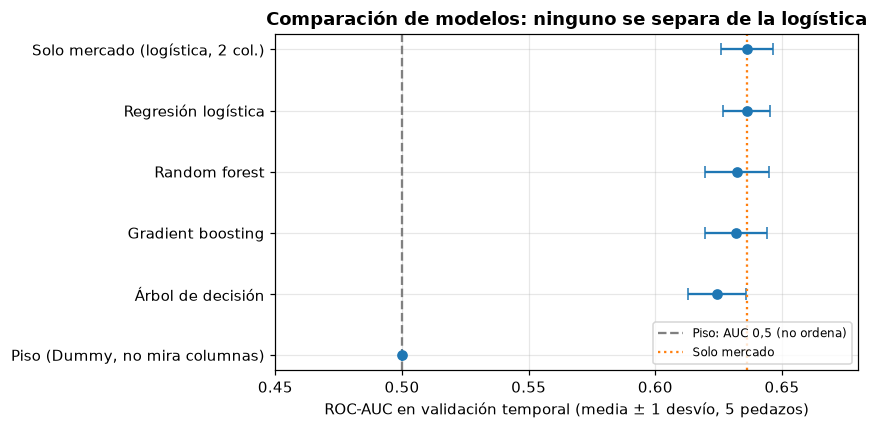

In [11]:
# la tabla dibujada: el punto es la AUC media en validación, la barra un desvío a cada lado
orden = comparacion.sort_values("AUC media").index
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(comparacion.loc[orden, "AUC media"], range(len(orden)), xerr=comparacion.loc[orden, "AUC desvío"],
            fmt="o", capsize=4, color="tab:blue")
ax.axvline(0.5, color="gray", linestyle="--", label="Piso: AUC 0,5 (no ordena)")
ax.axvline(comparacion.loc["Solo mercado (logística, 2 col.)", "AUC media"], color="tab:orange", linestyle=":",
           label="Solo mercado")
ax.set_yticks(range(len(orden)), orden)
ax.set_xlim(0.45, 0.68)
ax.set_xlabel("ROC-AUC en validación temporal (media ± 1 desvío, 5 pedazos)")
ax.set_title("Comparación de modelos: ninguno se separa de la logística")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### 3.2 La regla: el complejo tiene que ganarle al simple por más que el desvío

Dos maneras de mirarlo. La primera, la de la consigna: la diferencia de AUC media contra el desvío. La segunda, más fina:
como los cinco pedazos son **los mismos** para todos los modelos, se puede restar pedazo a pedazo (diferencia **pareada**) y ver
si el complejo le gana a la logística en todos, en algunos o en ninguno.

In [12]:
ref = resultados["Regresión logística"]
filas = {}
for nombre in ["Árbol de decisión", "Random forest", "Gradient boosting"]:
    r = resultados[nombre]
    dif_pareada = r["_por_pedazo"] - ref["_por_pedazo"]
    filas[nombre] = {
        "AUC media − logística": r["AUC media"] - ref["AUC media"],
        "mayor desvío de los dos": max(r["AUC desvío"], ref["AUC desvío"]),
        "pedazos en que gana": f"{(dif_pareada > 0).sum()} de {len(dif_pareada)}",
        "¿le gana por más que el desvío?": "sí" if r["AUC media"] - ref["AUC media"] > max(r["AUC desvío"], ref["AUC desvío"]) else "no",
    }
regla = pd.DataFrame(filas).T
regla

,AUC media − logística,mayor desvío de los dos,pedazos en que gana,¿le gana por más que el desvío?
Árbol de decisión,-0.011929,0.011437,0 de 5,no
Random forest,-0.004035,0.012613,2 de 5,no
Gradient boosting,-0.004159,0.012253,1 de 5,no


In [13]:
# la decisión, tomada por la regla y no a ojo
complejos_que_ganan = regla.index[regla["¿le gana por más que el desvío?"] == "sí"].tolist()
ELEGIDO = max(complejos_que_ganan, key=lambda n: resultados[n]["AUC media"]) if complejos_que_ganan else "Regresión logística"
print("Modelo elegido:", ELEGIDO)

Modelo elegido: Regresión logística


### 3.3 La complejidad, en una curva

¿Por qué los modelos más flexibles no ganan? La curva de validación del árbol lo muestra: a medida que crece la profundidad,
la AUC sobre lo que vio (train) sube sin parar y la de validación se estanca y después cae. El árbol empieza a memorizar
partidos en vez de aprender una regla. La logística, en cambio, casi no tiene brecha entre train y validación.

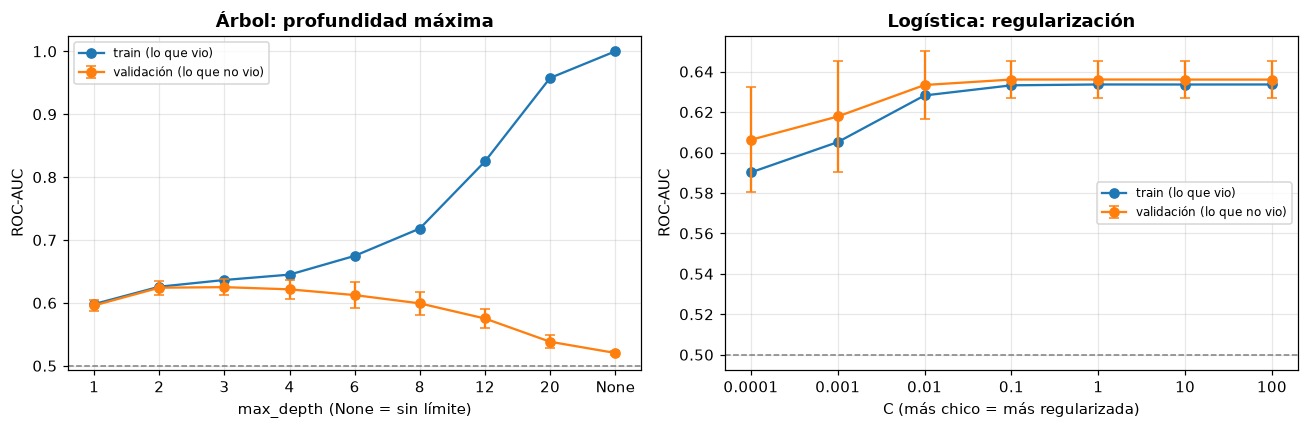

train  validación  desvío validación
árbol (max_depth) 1       0.5981      0.5960             0.0086
                  2       0.6257      0.6242             0.0114
                  3       0.6364      0.6251             0.0130
                  4       0.6450      0.6216             0.0155
                  6       0.6748      0.6125             0.0212
                  8       0.7183      0.5993             0.0185
                  12      0.8249      0.5752             0.0153
                  20      0.9576      0.5382             0.0106
                  None    1.0000      0.5204             0.0028
logística (C)     0.0001  0.5902      0.6063             0.0260
                  0.001   0.6051      0.6178             0.0276
                  0.01    0.6282      0.6334             0.0166
                  0.1     0.6332      0.6361             0.0092
                  1       0.6336      0.6361             0.0092
                  10      0.6336      0.6361             0.0093
                  100     0.6336      0.6360             0.0093

In [14]:
from sklearn.model_selection import validation_curve

def curva(pipeline, parametro, valores, ax, titulo, etiqueta_x):
    '''AUC en train y en validación temporal para cada valor de un hiperparámetro; devuelve los números.'''
    tr, va = validation_curve(pipeline, X_train, y_train, param_name=parametro, param_range=valores,
                              cv=cv, scoring="roc_auc", n_jobs=-1)
    x = [str(v) for v in valores]
    ax.plot(x, tr.mean(1), "o-", label="train (lo que vio)")
    ax.errorbar(x, va.mean(1), yerr=va.std(1), fmt="o-", capsize=3, label="validación (lo que no vio)")
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
    ax.set_title(titulo); ax.set_xlabel(etiqueta_x); ax.set_ylabel("ROC-AUC"); ax.legend(fontsize=8)
    return pd.DataFrame({"train": tr.mean(1), "validación": va.mean(1), "desvío validación": va.std(1)}, index=x).round(4)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
curva_arbol = curva(armar(DecisionTreeClassifier(random_state=SEMILLA)), "modelo__max_depth",
                    [1, 2, 3, 4, 6, 8, 12, 20, None], axes[0], "Árbol: profundidad máxima", "max_depth (None = sin límite)")
curva_C = curva(armar(LogisticRegression(max_iter=2000)), "modelo__C",
                [0.0001, 0.001, 0.01, 0.1, 1, 10, 100], axes[1], "Logística: regularización", "C (más chico = más regularizada)")
plt.tight_layout(); plt.show()
pd.concat({"árbol (max_depth)": curva_arbol, "logística (C)": curva_C})

### 3.4 ¿Y si los pedazos se armaran al azar?

La consigna advierte que una validación al azar sobre filas que no son independientes da números más altos que los reales.
Lo medimos: los mismos ganadores de cada familia, validados con `StratifiedKFold` mezclado al azar.

In [15]:
from sklearn.model_selection import StratifiedKFold

cv_azar = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
azar = {}
for nombre in ["Regresión logística", "Árbol de decisión", "Random forest", "Gradient boosting"]:
    r = evaluar(busquedas[nombre].best_estimator_, validacion=cv_azar)
    azar[nombre] = {"AUC temporal": resultados[nombre]["AUC media"], "AUC al azar": r["AUC media"],
                    "AUC train al azar": r["AUC train"]}
azar = pd.DataFrame(azar).T
azar["al azar − temporal"] = azar["AUC al azar"] - azar["AUC temporal"]
azar.round(4)

,AUC temporal,AUC al azar,AUC train al azar,al azar − temporal
Regresión logística,0.6361,0.6335,0.6379,-0.0025
Árbol de decisión,0.6242,0.6172,0.6264,-0.0070
Random forest,0.6321,0.6291,0.6565,-0.0029
Gradient boosting,0.6319,0.6324,0.6440,0.0005


**Cómo se lee.** Esperábamos que al azar el número subiera, y **no subió**: la diferencia es de milésimas y en general a
favor de la validación temporal. Tiene explicación: ninguna columna identifica al equipo, al jugador ni a la fecha. Son diferencias
de rating y probabilidades. Mezclar al azar no le regala al modelo nada que pueda memorizar de una fila para usar en otra. Las que
sí lo harían (`equipo_local`, `equipo_visitante`, `fecha`) quedaron afuera de Silver en la Entrega 2.

Que no haya diferencia **no** quiere decir que da lo mismo. La validación temporal sigue siendo la que imita el uso, porque la
aplicación predice partidos futuros. Y este resultado es, además, un chequeo de fuga: si alguna columna «supiera» algo del
partido o del equipo, el azar lo hubiera premiado.

## Parte 4 — El ajuste del elegido

La grilla completa del modelo elegido, no solo el ganador. Si la AUC casi no cambia entre valores, eso también es un resultado:
el modelo es estable y el hiperparámetro no es la palanca.

In [16]:
def tabla_de(busqueda):
    '''cv_results_ reducido a lo que se lee: hiperparámetros, AUC media y desvío en validación, AUC en train, log-loss.'''
    r = pd.DataFrame(busqueda.cv_results_)
    params = r["params"].apply(lambda p: ", ".join(f"{k.split('__')[-1]}={v}" for k, v in p.items()))
    return (pd.DataFrame({"hiperparámetros": params,
                          "AUC media": r["mean_test_auc"], "AUC desvío": r["std_test_auc"],
                          "AUC train": r["mean_train_auc"], "log-loss media": -r["mean_test_logloss"],
                          "ranking": r["rank_test_auc"]})
              .sort_values("ranking").set_index("hiperparámetros").round(4))

tabla_de(busquedas[ELEGIDO])

,AUC media,AUC desvío,AUC train,log-loss media,ranking
hiperparámetros,,,,,
C=1,0.6361,0.0092,0.6336,0.4815,1
C=0.1,0.6361,0.0092,0.6332,0.4815,2
C=10,0.6361,0.0093,0.6336,0.4816,3
C=0.01,0.6334,0.0166,0.6282,0.4829,4
C=0.001,0.6178,0.0276,0.6051,0.4888,5


In [17]:
mejor_pipeline = busquedas[ELEGIDO].best_estimator_
HIPERPARAMETROS = {k: v for k, v in busquedas[ELEGIDO].best_params_.items()}
print(ELEGIDO, HIPERPARAMETROS)

Regresión logística {'modelo__C': 1}


## Parte 5 — Las columnas: qué aporta cada una

Las columnas que probamos y no sirvieron también son evidencia. Tres preguntas, todas con el modelo elegido, la misma validación
y la diferencia **pareada** por pedazo:

1. **Por grupo**: ¿los jugadores le agregan algo al mercado?
2. **Sacando de a una**: ¿cuánto pierde el modelo sin cada una de las 12?
3. **Agregando de a una**: las 11 que la Entrega 2 dejó en rojo, ¿hubieran sumado?

In [18]:
from sklearn.base import clone

def con_columnas(numericas, categoricas=()):
    '''El pipeline elegido (mismo modelo, mismos hiperparámetros) con otras columnas.'''
    return armar(clone(mejor_pipeline.named_steps["modelo"]), numericas=numericas, categoricas=categoricas)

def diferencia(r, base):
    d = r["_por_pedazo"] - base["_por_pedazo"]
    return {"AUC media": r["AUC media"], "Δ AUC vs base": d.mean(), "desvío de Δ": d.std(),
            "pedazos en que mejora": f"{(d > 0).sum()} de {len(d)}", "log-loss media": r["log-loss media"]}

base_12 = evaluar(mejor_pipeline)
grupos = {
    "Solo prob. del underdog (1)": evaluar(con_columnas(["prob_no_favorito"])),
    "Solo mercado (2)":        evaluar(con_columnas(MERCADO)),
    "Solo jugadores (10)":     evaluar(con_columnas(JUGADORES)),
    "Mercado + jugadores (12)": base_12,
}
base_mercado = grupos["Solo mercado (2)"]
pd.DataFrame({n: diferencia(r, base_mercado) for n, r in grupos.items()}).T.rename(
    columns={"Δ AUC vs base": "Δ AUC vs solo mercado"})

,AUC media,Δ AUC vs solo mercado,desvío de Δ,pedazos en que mejora,log-loss media
Solo prob. del underdog (1),0.636985,0.000719,0.000825,4 de 5,0.481268
Solo mercado (2),0.636266,0.0,0.0,0 de 5,0.481334
Solo jugadores (10),0.598627,-0.037639,0.017226,0 de 5,0.492361
Mercado + jugadores (12),0.636087,-0.000179,0.002771,3 de 5,0.481536


**Solo jugadores** ordena bastante mejor que el piso (AUC ~0,60): los ratings sí tienen información sobre quién gana. Pero
**sumados al mercado no agregan nada** por encima del ruido. Es lo que anticipó la hipótesis 2 de la Entrega 2: las cuotas ya
incorporan quién es mejor equipo. El mercado «sabe» lo que dicen los ratings FIFA.

Y algo que no esperábamos: la **probabilidad del empate tampoco suma**. La del underdog sola ordena igual o mejor que las dos
columnas del mercado juntas.

In [19]:
# la columna derivada: probabilidades en su escala (logit) o tal cual, con las 12 y con la del underdog sola
def log_loss_por_pedazo(pipeline):
    return -cross_validate(pipeline, X_train, y_train, cv=cv, scoring="neg_log_loss", n_jobs=-1)["test_score"]

escala = {}
for nombre, columnas in [("12 columnas", FEATURE_COLUMNS), ("Solo prob. del underdog", ["prob_no_favorito"])]:
    con_logit = log_loss_por_pedazo(con_columnas(columnas))
    sin_logit = log_loss_por_pedazo(armar(clone(mejor_pipeline.named_steps["modelo"]), numericas=columnas, logit_prob=False))
    d = con_logit - sin_logit
    escala[nombre] = {"log-loss con logit": con_logit.mean(), "log-loss tal cual": sin_logit.mean(),
                      "Δ log-loss (logit − tal cual)": d.mean(), "desvío de Δ": d.std(),
                      "pedazos en que mejora": f"{(d < 0).sum()} de {len(d)}"}
pd.DataFrame(escala).T

,log-loss con logit,log-loss tal cual,Δ log-loss (logit − tal cual),desvío de Δ,pedazos en que mejora
12 columnas,0.481536,0.482527,-0.00099,0.000452,5 de 5
Solo prob. del underdog,0.481268,0.482488,-0.00122,0.000474,5 de 5


La AUC no cambia con la escala (el orden es el mismo), pero la **log-loss mejora con el logit en todos los pedazos**: con la
probabilidad tal cual, la logística no puede dibujar «la probabilidad del modelo = la del mercado» y se equivoca en los extremos.
Es la columna derivada que sí sirvió.

In [20]:
sacar = {NOMBRES[c]: diferencia(evaluar(con_columnas([x for x in FEATURE_COLUMNS if x != c])), base_12)
         for c in FEATURE_COLUMNS}
sacar = pd.DataFrame(sacar).T.rename(columns={"AUC media": "AUC sin la columna", "Δ AUC vs base": "Δ AUC al sacarla",
                                              "pedazos en que mejora": "pedazos en que mejora al sacarla"})
sacar.sort_values("Δ AUC al sacarla")

,AUC sin la columna,Δ AUC al sacarla,desvío de Δ,pedazos en que mejora al sacarla,log-loss media
Prob. implícita del underdog,0.617759,-0.018328,0.006189,0 de 5,0.485188
Dif. mejores reacciones,0.635571,-0.000516,0.000532,1 de 5,0.481613
Dif. rating de la defensa,0.635696,-0.00039,0.000942,2 de 5,0.481543
Dif. peor titular,0.635936,-0.00015,0.001531,2 de 5,0.481427
Dif. mejor jugador,0.636052,-0.000035,0.000893,2 de 5,0.481547
Dif. rating del ataque,0.636122,0.000035,0.000436,2 de 5,0.481485
Dif. mejor definición,0.636147,0.000061,0.000173,3 de 5,0.481465
Dif. rating del mediocampo,0.636205,0.000119,0.000519,3 de 5,0.481462
Dif. mejor marca,0.6363,0.000213,0.000499,3 de 5,0.481495
Dif. rating de los 3 mejores,0.63647,0.000384,0.00263,4 de 5,0.481447


In [21]:
agregar = {}
for c in ROJAS_NUM:
    agregar[NOMBRES[c]] = diferencia(evaluar(con_columnas(FEATURE_COLUMNS + [c])), base_12)
for c in ROJAS_CAT:
    agregar[NOMBRES[c]] = diferencia(evaluar(con_columnas(FEATURE_COLUMNS, categoricas=[c])), base_12)
agregar = pd.DataFrame(agregar).T.rename(columns={"AUC media": "AUC con la columna", "Δ AUC vs base": "Δ AUC al agregarla"})
agregar.sort_values("Δ AUC al agregarla", ascending=False)

,AUC con la columna,Δ AUC al agregarla,desvío de Δ,pedazos en que mejora,log-loss media
Favorito local / visitante,0.637473,0.001387,0.002439,3 de 5,0.481085
Dif. altura media del XI,0.636083,-0.000004,0.000153,3 de 5,0.48154
Dif. dispersión del XI,0.636021,-0.000065,0.000347,2 de 5,0.481541
Dif. jugador más fuerte,0.635908,-0.000179,0.001334,2 de 5,0.48159
Dif. rating del arquero,0.635837,-0.000249,0.002254,3 de 5,0.481623
Dif. edad media del XI,0.635767,-0.00032,0.000614,2 de 5,0.481606
Jornada,0.635291,-0.000796,0.001975,3 de 5,0.481728
Dif. jugador más rápido,0.635061,-0.001026,0.002196,3 de 5,0.481703
Liga,0.634648,-0.001439,0.003183,1 de 5,0.481972


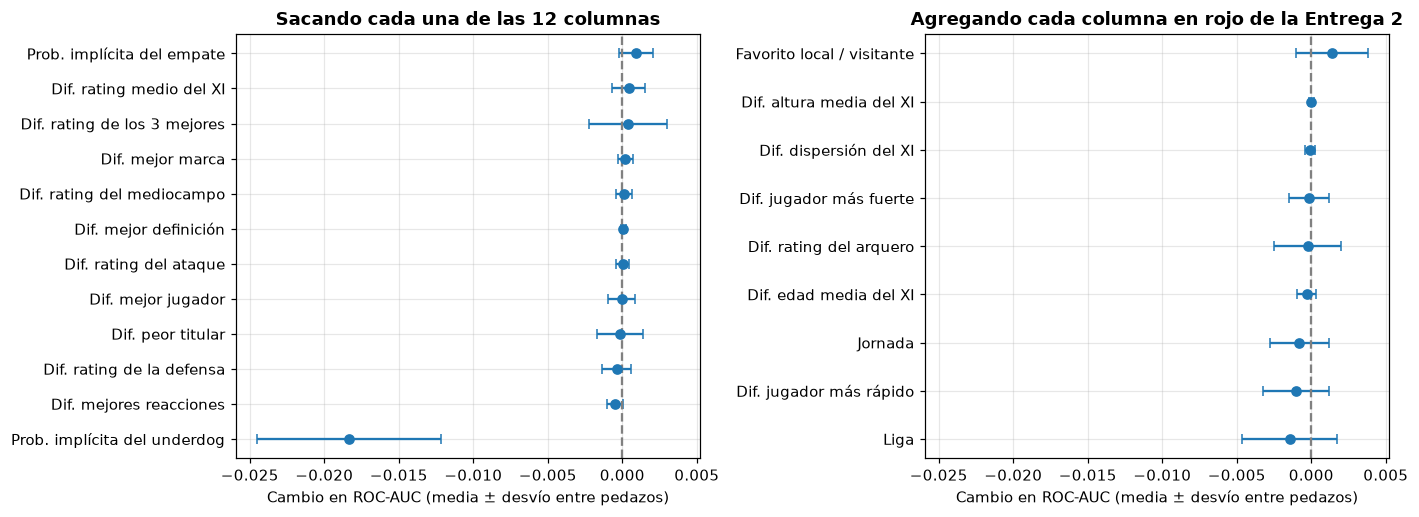

In [22]:
# las tres preguntas en un gráfico: cuánto cambia la AUC (media ± desvío de la diferencia pareada)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharex=True)
for ax, t, col, titulo in [(axes[0], sacar, "Δ AUC al sacarla", "Sacando cada una de las 12 columnas"),
                           (axes[1], agregar, "Δ AUC al agregarla", "Agregando cada columna en rojo de la Entrega 2")]:
    t = t.sort_values(col)
    ax.errorbar(t[col], range(len(t)), xerr=t["desvío de Δ"], fmt="o", capsize=3)
    ax.axvline(0, color="gray", linestyle="--")
    ax.set_yticks(range(len(t)), t.index); ax.set_title(titulo)
    ax.set_xlabel("Cambio en ROC-AUC (media ± desvío entre pedazos)")
plt.tight_layout(); plt.show()

In [23]:
# la decisión de columnas, con la MISMA regla que la de modelos: se arranca por el conjunto más chico y se pasa al siguiente
# solo si le gana por más que el desvío (diferencia pareada por pedazo)
d_jug = base_12["_por_pedazo"] - base_mercado["_por_pedazo"]
escalera = [("Solo prob. del underdog (1)", ["prob_no_favorito"]), ("Solo mercado (2)", MERCADO),
            ("Mercado + jugadores (12)", FEATURE_COLUMNS)]
actual, COLUMNAS_FINALES = escalera[0]
pasos = []
for nombre, columnas in escalera[1:]:
    d = grupos[nombre]["_por_pedazo"] - grupos[actual]["_por_pedazo"]
    gana = d.mean() > d.std()
    pasos.append({"de": actual, "a": nombre, "Δ AUC": d.mean(), "desvío de Δ": d.std(), "¿pasa?": "sí" if gana else "no"})
    if gana:
        actual, COLUMNAS_FINALES = nombre, columnas
display(pd.DataFrame(pasos).round(4))
print("Columnas del modelo final:", legible(COLUMNAS_FINALES))

,de,a,Δ AUC,desvío de Δ,¿pasa?
0,Solo prob. del underdog (1),Solo mercado (2),-0.0007,0.0008,no
1,Solo prob. del underdog (1),Mercado + jugadores (12),-0.0009,0.0027,no


Columnas del modelo final: ['Prob. implícita del underdog']


## Parte 6 — El desbalance como decisión

El underdog gana el 20% de las veces. Hay dos palancas, y cada una cuesta algo distinto:

- **`class_weight="balanced"`**: le dice a la pérdida que cada victoria del underdog vale ~4 veces más. Mueve las probabilidades
  hacia arriba.
- **Mover el umbral**: el modelo se entrena igual y se cambia el corte a partir del cual decimos «gana el underdog» (por defecto, 0,5).

Para elegir el umbral sin tocar el test se usan las predicciones **fuera de muestra** de la validación temporal: cada partido
del entrenamiento (salvo el primer bloque, que nunca se valida) recibe la probabilidad de un modelo que no lo vio.

In [24]:
from sklearn.metrics import precision_score, recall_score, f1_score

def fuera_de_muestra(pipeline):
    '''Probabilidad de "gana el underdog" para cada partido de validación, predicha por un modelo que solo vio el pasado.'''
    proba = pd.Series(np.nan, index=X_train.index)
    for tr, va in cv.split(X_train):
        p = clone(pipeline).fit(X_train.iloc[tr], y_train.iloc[tr])
        proba.iloc[va] = p.predict_proba(X_train.iloc[va])[:, 1]
    return proba.dropna()

def resumen(proba, y, umbral):
    pred = (proba >= umbral).astype(int)
    return {"AUC": roc_auc_score(y, proba), "log-loss": log_loss(y, proba), "prob. media predicha": proba.mean(),
            "precisión (clase gana)": precision_score(y, pred, zero_division=0),
            "recall (clase gana)": recall_score(y, pred), "f1 (clase gana)": f1_score(y, pred),
            "% partidos marcados «gana»": pred.mean()}

final_sin_peso = con_columnas(COLUMNAS_FINALES)
final_con_peso = con_columnas(COLUMNAS_FINALES).set_params(modelo__class_weight="balanced")

oof_sin = fuera_de_muestra(final_sin_peso)
oof_con = fuera_de_muestra(final_con_peso)
y_oof = y_train.loc[oof_sin.index]
print(f"Tasa real de victorias del underdog en esos partidos: {y_oof.mean():.3f}")

pd.DataFrame({"sin peso, umbral 0,5":        resumen(oof_sin, y_oof, 0.5),
              "class_weight=balanced, umbral 0,5": resumen(oof_con, y_oof, 0.5)}).T.round(4)

Tasa real de victorias del underdog en esos partidos: 0.201


,AUC,log-loss,prob. media predicha,precisión (clase gana),recall (clase gana),f1 (clase gana),% partidos marcados «gana»
"sin peso, umbral 0,5",0.6367,0.4813,0.1970,0.000,0.0000,0.000,0.0000
"class_weight=balanced, umbral 0,5",0.6366,0.6579,0.4777,0.261,0.6917,0.379,0.5332


**Lo que cuesta `class_weight`.** La AUC no cambia (el orden de los partidos es el mismo), pero la log-loss empeora: las
probabilidades quedan infladas (dice ~50% de media cuando la tasa real es ~20%). Para una aplicación que **muestra** la
probabilidad, eso es mentirle al usuario. Sin peso y con umbral 0,5, en cambio, el modelo casi nunca dice «gana»: la
probabilidad del underdog rara vez pasa de 0,5.

**Decisión: sin `class_weight` (probabilidades honestas) y con el umbral movido** para la respuesta de sí/no.

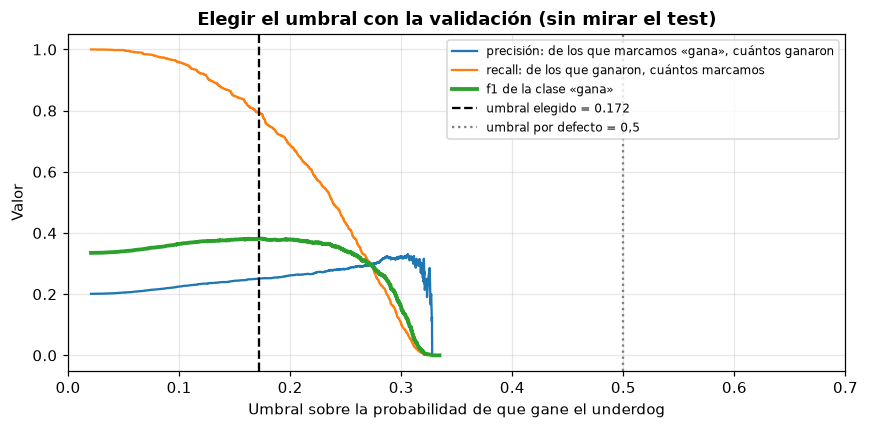

,AUC,log-loss,prob. media predicha,precisión (clase gana),recall (clase gana),f1 (clase gana),% partidos marcados «gana»
"umbral 0,5",0.6367,0.4813,0.197,0.0000,0.0000,0.0000,0.0000
umbral 0.172 (máx. f1),0.6367,0.4813,0.197,0.2517,0.7933,0.3821,0.6341


In [25]:
from sklearn.metrics import precision_recall_curve

prec, rec, umbrales = precision_recall_curve(y_oof, oof_sin)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
UMBRAL = float(umbrales[np.argmax(f1s)])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(umbrales, prec[:-1], label="precisión: de los que marcamos «gana», cuántos ganaron")
ax.plot(umbrales, rec[:-1], label="recall: de los que ganaron, cuántos marcamos")
ax.plot(umbrales, f1s, label="f1 de la clase «gana»", linewidth=2.5)
ax.axvline(UMBRAL, color="black", linestyle="--", label=f"umbral elegido = {UMBRAL:.3f}")
ax.axvline(0.5, color="gray", linestyle=":", label="umbral por defecto = 0,5")
ax.set_xlabel("Umbral sobre la probabilidad de que gane el underdog"); ax.set_ylabel("Valor")
ax.set_title("Elegir el umbral con la validación (sin mirar el test)"); ax.set_xlim(0, 0.7); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

pd.DataFrame({"umbral 0,5": resumen(oof_sin, y_oof, 0.5),
              f"umbral {UMBRAL:.3f} (máx. f1)": resumen(oof_sin, y_oof, UMBRAL)}).T.round(4)

## Parte 7 — El modelo final, medido una vez sobre el test

Todo lo que se eligió (familia, hiperparámetros, columnas, `class_weight` y umbral) se eligió arriba con validación sobre
2008/09–2014/15. Ahora se entrena con **todo** el entrenamiento y se mide **una sola vez** sobre la temporada 2015/16.
En la misma tabla van el piso y el mercado, medidos sobre el mismo test, como referencia (no se elige nada con ellos).

In [26]:
modelo_final = clone(final_sin_peso).fit(X_train, y_train)
proba_test = pd.Series(modelo_final.predict_proba(X_test)[:, 1], index=X_test.index)
pred_test = (proba_test >= UMBRAL).astype(int)

piso_test = armar(DummyClassifier(strategy="prior")).fit(X_train, y_train).predict_proba(X_test)[:, 1]
mercado_test = con_columnas(MERCADO).fit(X_train, y_train).predict_proba(X_test)[:, 1]

pd.DataFrame({
    "Piso (Dummy)":            {"AUC": 0.5, "log-loss": log_loss(y_test, piso_test)},
    "Cuota cruda (mercado, sin entrenar)": {"AUC": roc_auc_score(y_test, X_test["prob_no_favorito"]),
                                            "log-loss": log_loss(y_test, X_test["prob_no_favorito"])},
    "Solo mercado":            {"AUC": roc_auc_score(y_test, mercado_test), "log-loss": log_loss(y_test, mercado_test)},
    f"MODELO FINAL ({ELEGIDO})": {"AUC": roc_auc_score(y_test, proba_test), "log-loss": log_loss(y_test, proba_test)},
}).T.round(4)

,AUC,log-loss
Piso (Dummy),0.5000,0.5293
"Cuota cruda (mercado, sin entrenar)",0.6564,0.4983
Solo mercado,0.6563,0.4990
MODELO FINAL (Regresión logística),0.6564,0.4990


In [27]:
validacion_final = evaluar(final_sin_peso)
pd.DataFrame({"validación temporal (2010–2015)": {"AUC": validacion_final["AUC media"], "log-loss": validacion_final["log-loss media"],
                                                    "AUC desvío": validacion_final["AUC desvío"]},
              "test (2015/16, mirado una vez)":   {"AUC": roc_auc_score(y_test, proba_test), "log-loss": log_loss(y_test, proba_test),
                                                    "AUC desvío": np.nan}}).T.round(4)

,AUC,log-loss,AUC desvío
validación temporal (2010–2015),0.6370,0.4813,0.0105
"test (2015/16, mirado una vez)",0.6564,0.4990,NaN


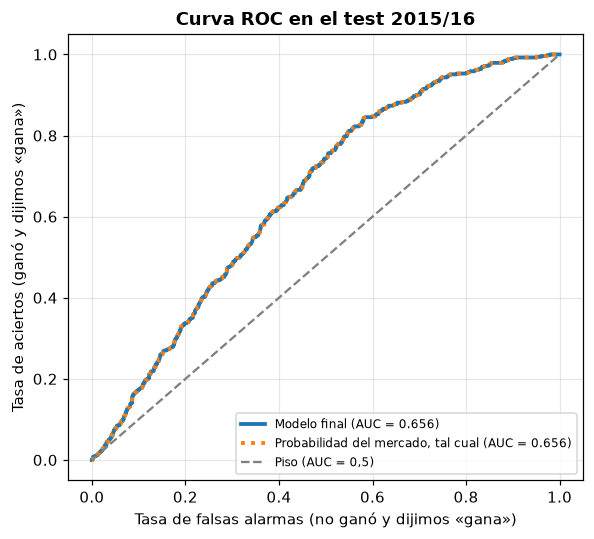

In [28]:
# la métrica declarada, dibujada: la curva ROC del test, contra el piso y contra la probabilidad del mercado
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(5.5, 5))
for puntaje, nombre, estilo in [(proba_test, "Modelo final", "-"), (X_test["prob_no_favorito"], "Probabilidad del mercado, tal cual", ":")]:
    fpr, tpr, _ = roc_curve(y_test, puntaje)
    ax.plot(fpr, tpr, estilo, linewidth=2.5, label=f"{nombre} (AUC = {roc_auc_score(y_test, puntaje):.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Piso (AUC = 0,5)")
ax.set_xlabel("Tasa de falsas alarmas (no ganó y dijimos «gana»)")
ax.set_ylabel("Tasa de aciertos (ganó y dijimos «gana»)")
ax.set_title("Curva ROC en el test 2015/16"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**Cómo se lee.** Cada punto de la curva es un umbral distinto: más a la derecha, más partidos marcamos como «gana» y detectamos
más sorpresas a costa de más falsas alarmas. El área bajo la curva es la AUC. La diagonal es el piso (tirar una moneda). La curva del
modelo final y la del mercado quedan **una encima de la otra**: es el mismo ordenamiento de partidos, porque el modelo es una función
creciente de la cuota.

### 7.1 Dónde se equivoca

La matriz de confusión con el umbral elegido, normalizada de las dos maneras:

- **por fila** (sobre lo real): de los partidos que el underdog ganó, qué parte detectamos (recall);
- **por columna** (sobre lo predicho): de los partidos que marcamos «gana», qué parte ganó de verdad (precisión).

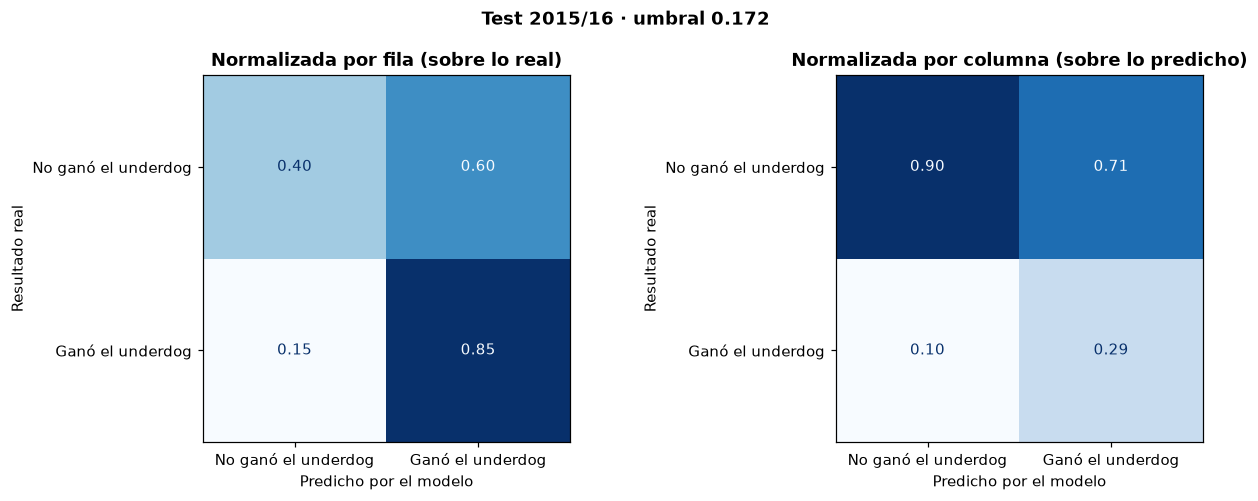

                     precision    recall  f1-score   support

No ganó el underdog      0.902     0.404     0.559      1869
   Ganó el underdog      0.287     0.845     0.429       530

           accuracy                          0.502      2399
          macro avg      0.595     0.625     0.494      2399
       weighted avg      0.766     0.502     0.530      2399



In [29]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, norm, titulo in [(axes[0], "true", "Normalizada por fila (sobre lo real)"),
                         (axes[1], "pred", "Normalizada por columna (sobre lo predicho)")]:
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test, normalize=norm, display_labels=CLASES,
                                            values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(titulo); ax.set_xlabel("Predicho por el modelo"); ax.set_ylabel("Resultado real"); ax.grid(False)
fig.suptitle(f"Test 2015/16 · umbral {UMBRAL:.3f}", fontweight="bold")
plt.tight_layout(); plt.show()

print(classification_report(y_test, pred_test, target_names=CLASES, digits=3))

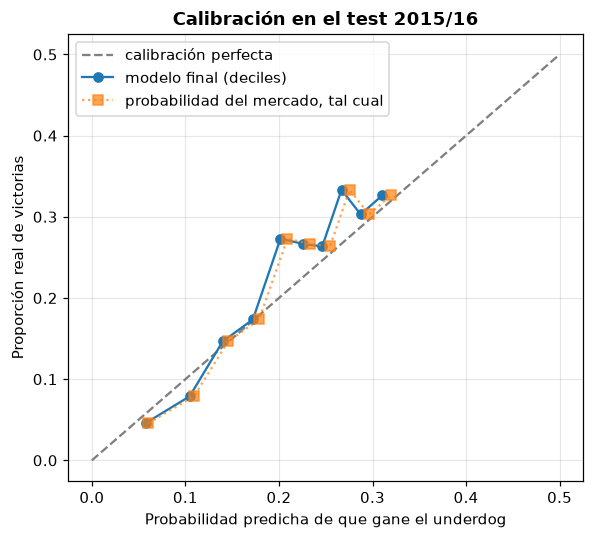

,partidos,prob. predicha media,tasa real de victorias,prob. del mercado media
decil de prob. predicha,,,,
2–8%,240,0.057,0.046,0.060
8–12%,241,0.104,0.079,0.109
12–16%,239,0.140,0.146,0.146
16–19%,242,0.172,0.174,0.179
19–21%,238,0.202,0.273,0.209
21–24%,240,0.226,0.267,0.233
24–26%,239,0.246,0.264,0.255
26–28%,240,0.267,0.333,0.276
28–30%,241,0.287,0.303,0.296


In [30]:
# ¿Las probabilidades son creíbles? Se agrupan los partidos por probabilidad predicha y se compara con lo que pasó
tramos = pd.qcut(proba_test, 10)
tramos = tramos.cat.rename_categories([f"{100 * i.left:.0f}–{100 * i.right:.0f}%" for i in tramos.cat.categories])
calib = (pd.DataFrame({"prob. predicha media": proba_test, "tasa real": y_test})
           .groupby(tramos, observed=True).agg(["mean", "size"]))
calib = pd.DataFrame({"partidos": calib[("tasa real", "size")],
                      "prob. predicha media": calib[("prob. predicha media", "mean")],
                      "tasa real de victorias": calib[("tasa real", "mean")]})

calib["prob. del mercado media"] = prueba["prob_no_favorito"].groupby(tramos.values, observed=True).mean().values

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 0.5], [0, 0.5], "--", color="gray", label="calibración perfecta")
ax.plot(calib["prob. predicha media"], calib["tasa real de victorias"], "o-", label="modelo final (deciles)")
ax.plot(calib["prob. del mercado media"], calib["tasa real de victorias"], "s:", alpha=0.7, label="probabilidad del mercado, tal cual")
ax.set_xlabel("Probabilidad predicha de que gane el underdog"); ax.set_ylabel("Proporción real de victorias")
ax.set_title("Calibración en el test 2015/16"); ax.legend()
plt.tight_layout(); plt.show()
calib.rename_axis("decil de prob. predicha").round(3)

**Cómo se lee.** En los extremos el modelo está bien calibrado: cuando dice 6%, el underdog gana el 5%. En los deciles del medio
(19% a 28%), en 2015/16 el underdog ganó **más** de lo que decía el modelo (27% contra 20–23%). Pero el mercado se equivocó
exactamente igual (los cuadrados del gráfico van pegados a los círculos): fue una **temporada con más sorpresas** (22,1% de
victorias del underdog contra 20,1% en el entrenamiento; es la temporada en que el Leicester salió campeón de la Premier). Un
modelo entrenado con el pasado no puede saber que la temporada que viene va a ser más sorpresiva, y el mercado tampoco lo supo.

In [31]:
# en qué tramo erra más: por qué tan claro era el favorito según el mercado
tramo = pd.cut(prueba["prob_favorito"], [0, 0.45, 0.55, 0.65, 0.75, 1],
               labels=["≤ 0,45 (parejo)", "0,45–0,55", "0,55–0,65", "0,65–0,75", "> 0,75 (favorito claro)"])
por_tramo = pd.DataFrame({"y": y_test, "p": proba_test, "pred": pred_test, "tramo": tramo}).groupby("tramo", observed=True)
pd.DataFrame({
    "partidos":                  por_tramo.size(),
    "tasa real gana underdog":   por_tramo["y"].mean(),
    "prob. media predicha":      por_tramo["p"].mean(),
    "AUC dentro del tramo":      por_tramo.apply(lambda g: roc_auc_score(g["y"], g["p"]) if g["y"].nunique() > 1 else np.nan),
    "recall (ganó y lo marcamos)": por_tramo.apply(lambda g: g.loc[g["y"] == 1, "pred"].mean()),
    "% marcados «gana»":         por_tramo["pred"].mean(),
}).rename_axis("probabilidad del favorito").round(3)

,partidos,tasa real gana underdog,prob. media predicha,AUC dentro del tramo,recall (ganó y lo marcamos),% marcados «gana»
probabilidad del favorito,,,,,,
"≤ 0,45 (parejo)",683,0.315,0.288,0.509,1.000,1.000
"0,45–0,55",773,0.273,0.226,0.528,0.995,0.995
"0,55–0,65",444,0.160,0.157,0.545,0.324,0.245
"0,65–0,75",275,0.098,0.105,0.488,0.000,0.000
"> 0,75 (favorito claro)",224,0.027,0.056,0.469,0.000,0.000


**Dónde se equivoca.** Dos cosas salen de esta tabla:

1. **Adentro de cada tramo, la AUC es ~0,5.** Entre partidos con cuotas parecidas, el modelo no distingue cuál va a ser la
   sorpresa: toda su información es el nivel de la cuota. Distinguir *entre* tramos sí lo hace (del 31% al 3% de victorias).
2. **El umbral elegido equivale a una regla simple**: marcar «gana el underdog» en los partidos parejos (favorito con menos de
   ~0,55–0,60 de probabilidad) y «no gana» en el resto. Por eso el recall es 1 en los tramos parejos y 0 en los desparejos.

La respuesta de sí/no es la parte débil del modelo: con umbral máximo-f1 marca «gana» en ~60% de los partidos para acertar el
29% de las veces (contra 22% de base). **Para la aplicación, lo que tiene valor es la probabilidad, no el sí/no.**

In [32]:
# errores concretos, con nombre y apellido: el auditoría tiene equipos y resultado (solo para leer, nunca como feature)
auditoria = pd.read_parquet(AUDIT_DIR / "match_audit.parquet",
                            columns=["match_id", "equipo_local", "equipo_visitante", "goles_local", "goles_visitante"])
casos = (prueba[["match_id", "fecha", "liga", "equipo_favorito", "prob_favorito", "prob_no_favorito", TARGET_COLUMN]]
         .assign(prob_modelo=proba_test.values).merge(auditoria, on="match_id"))
casos["underdog"] = np.where(casos["equipo_favorito"] == "local", casos["equipo_visitante"], casos["equipo_local"])
casos["favorito"] = np.where(casos["equipo_favorito"] == "local", casos["equipo_local"], casos["equipo_visitante"])
casos["resultado"] = casos["equipo_local"] + " " + casos["goles_local"].astype(str) + "–" + casos["goles_visitante"].astype(str) + " " + casos["equipo_visitante"]
ver = ["fecha", "liga", "favorito", "underdog", "prob_no_favorito", "prob_modelo", "resultado"]

print("Las 5 sorpresas más grandes (ganó el underdog y el modelo le daba muy poco):")
display(casos[casos[TARGET_COLUMN] == 1].nsmallest(5, "prob_modelo")[ver].round(3))
print("Las 5 falsas alarmas más grandes (el modelo le daba más chance y no ganó):")
display(casos[casos[TARGET_COLUMN] == 0].nlargest(5, "prob_modelo")[ver].round(3))

Las 5 sorpresas más grandes (ganó el underdog y el modelo le daba muy poco):


,fecha,liga,favorito,underdog,prob_no_favorito,prob_modelo,resultado
1111,2015-12-19,Scotland Premier League,Celtic,Motherwell,0.042,0.039,Celtic 1–2 Motherwell
1747,2016-03-02,Germany 1. Bundesliga,FC Bayern Munich,1. FSV Mainz 05,0.044,0.042,FC Bayern Munich 1–2 1. FSV Mainz 05
2328,2016-05-08,Spain LIGA BBVA,Atlético Madrid,Levante UD,0.052,0.049,Levante UD 2–1 Atlético Madrid
2123,2016-04-17,Spain LIGA BBVA,FC Barcelona,Valencia CF,0.057,0.054,FC Barcelona 1–2 Valencia CF
278,2015-09-12,Germany 1. Bundesliga,Bayer 04 Leverkusen,SV Darmstadt 98,0.074,0.071,Bayer 04 Leverkusen 0–1 SV Darmstadt 98


Las 5 falsas alarmas más grandes (el modelo le daba más chance y no ganó):


,fecha,liga,favorito,underdog,prob_no_favorito,prob_modelo,resultado
2101,2016-04-16,Germany 1. Bundesliga,SV Werder Bremen,VfL Wolfsburg,0.345,0.336,SV Werder Bremen 3–2 VfL Wolfsburg
2325,2016-05-08,Spain LIGA BBVA,Granada CF,Sevilla FC,0.343,0.333,Sevilla FC 1–4 Granada CF
2361,2016-05-14,Germany 1. Bundesliga,VfL Wolfsburg,VfB Stuttgart,0.342,0.333,VfL Wolfsburg 3–1 VfB Stuttgart
1063,2015-12-13,Netherlands Eredivisie,PEC Zwolle,AZ,0.338,0.328,PEC Zwolle 2–1 AZ
2313,2016-05-08,England Premier League,Manchester City,Arsenal,0.336,0.327,Manchester City 2–2 Arsenal


**Una explicación desde el fútbol.**

- **Las sorpresas más grandes** son gigantes que pierden de local contra equipos chicos: el Bayern 1–2 con el Mainz, el
  Barcelona 1–2 con el Valencia, el Leverkusen 0–1 con el Darmstadt recién ascendido. El modelo les daba 4% a 7% a los underdogs,
  igual que el mercado. **No son errores de lectura**: con 1 chance en 20, de cada 20 partidos así el underdog gana uno. El fútbol
  tiene pocos goles, y uno solo (un penal, un error del arquero, una expulsión) decide el partido. Ninguna columna pre-partido
  contiene eso.
- **Las falsas alarmas** son partidos con el underdog cerca del 33%, casi parejos: el modelo les da la máxima chance y aun así
  lo más probable es que el underdog no gane (2 de cada 3 veces). No hay una confusión del modelo que explicar: es la
  incertidumbre misma del partido.

### 7.2 En qué se apoya

Dos lecturas: los **coeficientes** de la logística (las columnas están escaladas, así que se comparan entre sí; el signo dice
hacia dónde empuja) y la **importancia por permutación** sobre el test (cuánto cae la AUC si se desordena esa columna).

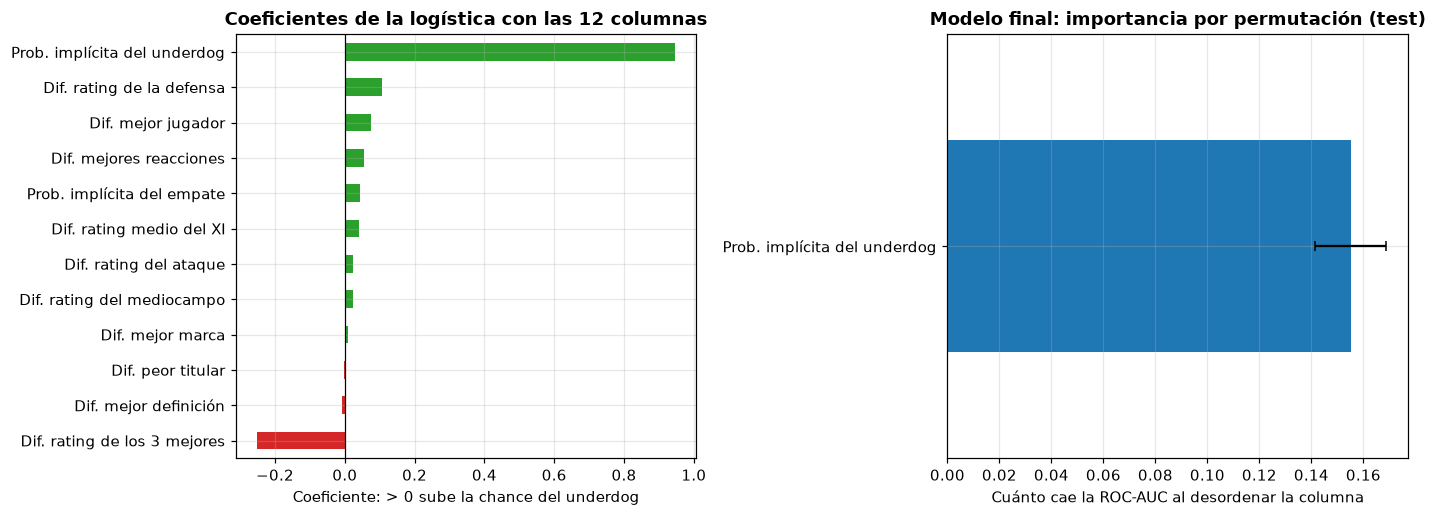

Modelo final: logit(p) = -0.039 +1.004 · logit(prob. del mercado)


,coef. modelo final,coef. modelo con 12
Prob. implícita del underdog,1.0044,0.9475
Dif. rating de los 3 mejores,NaN,-0.2523
Dif. mejor definición,NaN,-0.0082
Dif. peor titular,NaN,-0.0026
Dif. mejor marca,NaN,0.0102
Dif. rating del mediocampo,NaN,0.0229
Dif. rating del ataque,NaN,0.0246
Dif. rating medio del XI,NaN,0.0393
Prob. implícita del empate,NaN,0.0441
Dif. mejores reacciones,NaN,0.0539


In [33]:
from sklearn.inspection import permutation_importance

def coeficientes(pipeline):
    '''Coeficientes de la logística con el nombre legible de la columna que entra (en el orden del ColumnTransformer).'''
    columnas = [n.split("__", 1)[1] for n in pipeline.named_steps["preparar"].get_feature_names_out()]
    return pd.Series(pipeline.named_steps["modelo"].coef_[0], index=legible(columnas)).sort_values()

perm = permutation_importance(modelo_final, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEMILLA, n_jobs=-1)
importancia = (pd.DataFrame({"caída de AUC (media)": perm.importances_mean, "desvío": perm.importances_std}, index=legible(CANDIDATAS))
                 .loc[legible(COLUMNAS_FINALES)].sort_values("caída de AUC (media)"))

# como referencia, el modelo con las 12: qué peso les da a los jugadores cuando compiten con el mercado
coef_12 = coeficientes(clone(con_columnas(FEATURE_COLUMNS)).fit(X_train, y_train))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
coef_12.plot.barh(ax=axes[0], color=np.where(coef_12 > 0, "tab:green", "tab:red"))
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Coeficientes de la logística con las 12 columnas"); axes[0].set_xlabel("Coeficiente: > 0 sube la chance del underdog")
importancia["caída de AUC (media)"].plot.barh(ax=axes[1], xerr=importancia["desvío"], capsize=3)
axes[1].set_title("Modelo final: importancia por permutación (test)"); axes[1].set_xlabel("Cuánto cae la ROC-AUC al desordenar la columna")
plt.tight_layout(); plt.show()

m = modelo_final.named_steps["modelo"]
print(f"Modelo final: logit(p) = {m.intercept_[0]:+.3f} {m.coef_[0][0]:+.3f} · logit(prob. del mercado)")
pd.concat({"coef. modelo final": coeficientes(modelo_final), "coef. modelo con 12": coef_12}, axis=1).round(4)

**Cómo se leen.** El modelo final tiene una sola columna, `logit(prob. del mercado)`, y aprendió un **coeficiente casi
exactamente 1 y un intercepto casi 0**. Es la función identidad: el modelo aprendió que **la mejor estimación de la chance del
underdog es la que ya publica el mercado**. Si las casas sobrestimaran o subestimaran al underdog, el coeficiente se iría de 1
(eso es lo que se conoce como *sesgo favorito–longshot*). En esta base, con un margen sacado, no lo vemos.

Por eso el modelo final empata con la cuota cruda: **es** la cuota cruda, verificada.

Las 12 columnas escaladas (salvo las probabilidades, que van en logit) se comparan entre sí por el tamaño del coeficiente.

En el modelo con 12 aparece un **signo que no tiene sentido de fútbol**: «Dif. rating de los 3 mejores» es negativo, como si
tener mejores figuras le restara al underdog. No es un hallazgo. Es **colinealidad**: el rating medio, el de los 3 mejores y
el del mejor jugador correlacionan entre 0,86 y 0,96 (Entrega 2). La logística reparte el peso entre columnas que dicen lo mismo,
y los signos individuales dejan de ser interpretables. Es otra razón para no usar las 12.

La importancia por permutación del modelo final es la de su única columna: si se desordena la probabilidad del mercado, la AUC
cae hasta el piso (0,5). Todo lo que el modelo sabe viene de ahí.

## Parte 8 — Fuga, lo que no anduvo y el modelo guardado

### 8.1 La columna que más pesa: ¿fuga?

La que más pesa es la **probabilidad implícita del underdog**. No nos sorprende, y aun así la revisamos como sospechosa:

In [34]:
from sklearn.metrics import roc_auc_score as auc
chequeos = pd.Series({
    "AUC de la cuota cruda sola (test)":                 auc(y_test, X_test["prob_no_favorito"]),
    "Tope del DAG para una columna sola (falla si la supera)": 0.90,
    "Brecha AUC train − validación (modelo final)":      validacion_final["AUC train"] - validacion_final["AUC media"],
    "AUC al azar − AUC temporal (logística)":            azar.loc["Regresión logística", "al azar − temporal"],
    "AUC validación − AUC test (modelo final)":          validacion_final["AUC media"] - roc_auc_score(y_test, proba_test),
})
chequeos.round(4).to_frame("valor")

,valor
AUC de la cuota cruda sola (test),0.6564
Tope del DAG para una columna sola (falla si la supera),0.9000
Brecha AUC train − validación (modelo final),-0.0070
AUC al azar − AUC temporal (logística),-0.0025
AUC validación − AUC test (modelo final),-0.0194


- **Existe antes del partido.** Sale de las cuotas 1X2 que las casas publican días antes; los goles y el resultado nunca
  entran a Silver (hard check `sin_columnas_de_fuga` del DAG).
- **No predice demasiado.** Sola da una AUC de ~0,64, lejos del 0,90 a partir del cual el DAG falla por «predictor perfecto».
  Una columna con la respuesta adentro daría cerca de 1.
- **No hay brecha** entre train y validación, ni entre validación y test, ni entre validación temporal y al azar: no hay nada
  que el modelo vea en entrenamiento y no tenga después.
- **Tiene sentido del dominio**: es la opinión del mercado, que ya agrega forma, lesiones, localía y calidad del plantel.
- **Su coeficiente es ~1**: si la columna tuviera información del resultado, el modelo la usaría «de más» y el coeficiente
  se dispararía. Acá el modelo solo la confirma.

In [35]:
lo_que_no_anduvo = pd.DataFrame([
    {"qué probamos": "Árbol, random forest y gradient boosting (con grilla)",
     "resultado": f"ninguno le ganó a la logística por más que el desvío (mejor: {comparacion.drop(index=['Regresión logística', 'Solo mercado (logística, 2 col.)', 'Piso (Dummy, no mira columnas)'])['AUC media'].max():.4f} vs {resultados['Regresión logística']['AUC media']:.4f})"},
    {"qué probamos": "Los 10 gaps de jugadores sumados al mercado",
     "resultado": f"Δ AUC {d_jug.mean():+.4f} ± {d_jug.std():.4f}: no superan el ruido"},
    {"qué probamos": "Las 11 columnas en rojo de la Entrega 2 (de a una)",
     "resultado": f"ninguna mejora más que su desvío (máx. Δ AUC {agregar['Δ AUC al agregarla'].max():+.4f})"},
    {"qué probamos": "La probabilidad del empate junto a la del underdog",
     "resultado": f"no suma (Δ AUC {pasos[0]['Δ AUC']:+.4f} ± {pasos[0]['desvío de Δ']:.4f})"},
    {"qué probamos": "class_weight='balanced'",
     "resultado": "misma AUC, peor log-loss: infla las probabilidades"},
    {"qué probamos": "Validar al azar en vez de en el tiempo",
     "resultado": f"no cambia (logística {azar.loc['Regresión logística', 'al azar − temporal']:+.4f}): ninguna columna identifica equipo ni fecha"},
]).set_index("qué probamos")
lo_que_no_anduvo

,resultado
qué probamos,
"Árbol, random forest y gradient boosting (con grilla)",ninguno le ganó a la logística por más que el desvío (mejor: 0.6321 vs 0.6361)
Los 10 gaps de jugadores sumados al mercado,Δ AUC -0.0002 ± 0.0028: no superan el ruido
Las 11 columnas en rojo de la Entrega 2 (de a una),ninguna mejora más que su desvío (máx. Δ AUC +0.0014)
La probabilidad del empate junto a la del underdog,no suma (Δ AUC -0.0007 ± 0.0008)
class_weight='balanced',"misma AUC, peor log-loss: infla las probabilidades"
Validar al azar en vez de en el tiempo,no cambia (logística -0.0025): ninguna columna identifica equipo ni fecha


In [36]:
# el modelo para la Entrega 4: el pipeline entero (imputar + escalar + modelo) y lo necesario para usarlo
import joblib

MODELOS_DIR = DATA_DIR / "models"
MODELOS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(modelo_final, MODELOS_DIR / "underdog_modelo.joblib")

ficha = {
    "modelo": ELEGIDO, "hiperparametros": {k: str(v) for k, v in HIPERPARAMETROS.items()},
    "columnas": COLUMNAS_FINALES, "umbral": UMBRAL, "semilla": SEMILLA,
    "entrenado_con": f"{entrenamiento['temporada'].min()} a {entrenamiento['temporada'].max()} ({len(entrenamiento)} partidos)",
    "validacion": {"esquema": "TimeSeriesSplit(5)", "auc_media": validacion_final["AUC media"], "auc_desvio": validacion_final["AUC desvío"],
                   "logloss_media": validacion_final["log-loss media"]},
    "test": {"temporada": TEST_TEMPORADA, "auc": roc_auc_score(y_test, proba_test), "logloss": log_loss(y_test, proba_test),
             "f1_clase_gana": f1_score(y_test, pred_test)},
    "sklearn": sklearn.__version__,
}
(MODELOS_DIR / "underdog_modelo.json").write_text(json.dumps(ficha, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(ficha, indent=2, ensure_ascii=False))

{
  "modelo": "Regresión logística",
  "hiperparametros": {
    "modelo__C": "1"
  },
  "columnas": [
    "prob_no_favorito"
  ],
  "umbral": 0.17233952918877632,
  "semilla": 42,
  "entrenado_con": "2008/2009 a 2014/2015 (15560 partidos)",
  "validacion": {
    "esquema": "TimeSeriesSplit(5)",
    "auc_media": 0.6369847251222689,
    "auc_desvio": 0.010490375266942313,
    "logloss_media": 0.48126765773144903
  },
  "test": {
    "temporada": "2015/2016",
    "auc": 0.6563927839526736,
    "logloss": 0.49903014557559366,
    "f1_clase_gana": 0.4285031085604974
  },
  "sklearn": "1.9.1"
}


## Conclusión

**Qué predecimos**: si gana el underdog (20% de las veces). **Métrica**: ROC-AUC (ordenar los partidos por chance de sorpresa),
con log-loss de secundaria (que la probabilidad sea creíble). **Validación**: temporal, `TimeSeriesSplit(5)` sobre 2008/09–2014/15,
con 2015/16 como test mirado una vez.

**El resultado:**

| | AUC validación | AUC test | log-loss test |
|---|---:|---:|---:|
| Piso (Dummy) | 0,500 | 0,500 | 0,529 |
| Cuota cruda del mercado | 0,637 | 0,656 | 0,498 |
| **Modelo final**: logística sobre `logit(prob. del underdog)` | **0,637 ± 0,010** | **0,656** | **0,499** |

1. **Le gana al piso por mucho más que el ruido**: +0,14 de AUC con un desvío de 0,01, y 0,03 menos de log-loss en el test.
2. **Ningún modelo más complejo le ganó a la logística**: árbol, random forest y boosting quedaron entre 0,004 y 0,012 por
   debajo, dentro del desvío. El árbol sin límite memoriza (AUC 1,0 en train, 0,52 en validación).
3. **Los jugadores no agregan nada sobre el mercado.** Solos ordenan (AUC 0,60), pero sumados a la cuota la diferencia es de
   0,0002 ± 0,003. Lo anticipó la hipótesis 2 de la Entrega 2 y ahora está medido con un modelo.
4. **El modelo aprendió la identidad**: `logit(p) = −0,04 + 1,00 · logit(prob. del mercado)`. La probabilidad que publican las
   casas (con el margen sacado) ya está calibrada para el underdog. **Ese es el hallazgo**: el mercado de apuestas ya incorpora
   la calidad de los titulares, la localía, la liga y el resto de las columnas que construimos.

**¿El modelo dice algo que los datos solos no decían?** Sí, aunque no es lo que esperábamos al plantear la pregunta: dice que
**no hay información pública pre-partido, de las que tenemos, que mejore a las cuotas**, y lo dice con evidencia (comparación,
ablación de columnas, coeficiente ~1). Esperábamos que la calidad del XI titular, conocida una hora antes del partido,
le ganara a cuotas publicadas días antes. No pasó.

**Para la Entrega 4**: la aplicación usa este modelo (`include/data/models/underdog_modelo.joblib`), muestra la **probabilidad**
y puede mostrar, como contexto, las diferencias del XI. Lo que no puede prometer es saber más que las casas de apuestas.
Una mejora real necesitaría información que las cuotas no tengan: cuotas de cierre (más cercanas al pitazo) contra las de
apertura, o datos de forma reciente y lesiones.